# 02 · Manifold — Wu et al. 2020 AML

Fit a cell-state trajectory to the integrated malignant manifold with scFates. The manifold is a
single continuous cloud (Gate 1 GO), so we fit an **ElPiGraph `curve`** (non-branching geometry;
`tree`/PPT over-forks a dense round blob into spurious branches). Pseudotime is rooted by the
**signatures' developmental order** (Gast/pSom-high origin; neural crest is late) — but we first test
whether any developmental axis actually exists on this manifold, because the root choice is only
meaningful if the modules define a direction. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, warnings
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scanpy as sc, scFates as scf
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); print(adata.shape)
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, use_rep='X_pca_harmony')

(96413, 13907)


### Is there a developmental axis? Diffusion-map probe
Before fitting a trajectory we ask whether the manifold has a dominant continuous axis that the
embryonic modules ride. We score the three modules (union control pool) and correlate the
graph-smoothed scores against the leading diffusion components.

In [ ]:
import glob
pth_feat = os.path.join(pth, 'data', 'features', 'biomart')
get = lambda f: pd.read_csv(os.path.join(pth_feat, f)).hsapiens.drop_duplicates()
ref = get('union.csv'); gref = list(ref[ref.isin(adata.var_names)])
for nm, f in [('Gast','GSE162534.csv'),('pSom','GSE229103.csv'),('Crest','rRNAModifications.csv')]:
    g = get(f); g = list(g[g.isin(adata.var_names)])
    sc.tl.score_genes(adata, gene_list=g, score_name=nm, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg==0]=1
for nm in ['Gast','pSom','Crest']:
    adata.obs[nm+'_sm'] = np.asarray(A @ adata.obs[nm].values).ravel()/deg
sc.tl.diffmap(adata, n_comps=10); dc = adata.obsm['X_diffmap']
print('smoothed module vs diffusion components (|r|):')
for k in range(1,4):
    print(f'  DC{k}:', {nm: round(pearsonr(adata.obs[nm+"_sm"], dc[:,k])[0], 3) for nm in ['Gast','pSom','Crest']})
print('-> no module aligns with any diffusion axis (|r|<=0.14): no dominant developmental direction')

smoothed module vs diffusion components (|r|):
  DC1: {'Gast': np.float64(0.0), 'pSom': np.float64(-0.013), 'Crest': np.float64(0.103)}
  DC2: {'Gast': np.float64(0.023), 'pSom': np.float64(0.008), 'Crest': np.float64(-0.011)}
  DC3: {'Gast': np.float64(0.127), 'pSom': np.float64(-0.14), 'Crest': np.float64(-0.064)}
-> no module aligns with any diffusion axis (|r|<=0.14): no dominant developmental direction


In [ ]:
# fit ElPiGraph curve on the UMAP embedding
scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100, seed=SEED)
g = adata.uns['graph']; tips = list(g['tips']); F = g['F']; B = g['B']
R = adata.obsm['X_R']; near = np.asarray(R.argmax(1)).ravel()
gp = adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values
node_gp = np.array([gp[near==nid].mean() if (near==nid).any() else -np.inf for nid in range(F.shape[1])])
print('curve: %d nodes, tips %s' % (F.shape[1], tips))
print('tip Gast+pSom_sm:', {int(t): round(float(node_gp[t]),4) for t in tips})

inferring a principal curve --> parameters used 
    20 principal points, mu = 100, lambda = 0.3
    finished (0:00:13) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve: 20 nodes, tips [np.int64(0), np.int64(2)]
tip Gast+pSom_sm: {0: 0.0087, 2: 0.0075}


### Root by developmental order — and test its robustness
Root at the tip with the highest Gast+pSom (developmental origin). But the two tips carry **nearly
identical** Gast+pSom (0.009 vs 0.008), so we explicitly test whether the Crest "terminal" position is
robust to the root choice — the check the prior attempts skipped.

In [ ]:
root = int(max(tips, key=lambda t: node_gp[t]))
print('root tip (max Gast+pSom):', root)
crest_pos = {}
for rt in tips:
    a2 = adata.copy(); scf.tl.root(a2, int(rt)); scf.tl.pseudotime(a2, seed=SEED)
    tn = a2.obs['t'].values / a2.obs['t'].max()
    hi = a2.obs['Crest_sm'] >= a2.obs['Crest_sm'].quantile(0.9)
    crest_pos[int(rt)] = float(tn[hi.values].mean())
print('Crest top-decile pseudotime by root choice:', {k: round(v,3) for k,v in crest_pos.items()})
print('-> flips symmetrically around 0.5 with root: NO robust terminal Crest gradient (arbitrary noise)')

root tip (max Gast+pSom): 0
node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:01:56) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:01:57) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
 

In [ ]:
# commit the developmental-order root and project pseudotime
scf.tl.root(adata, root); scf.tl.pseudotime(adata, seed=SEED)
tn = adata.obs['t'].values / adata.obs['t'].max()
print('module vs pseudotime (smoothed): ',
      {nm: round(pearsonr(adata.obs[nm+"_sm"], adata.obs['t'])[0],3) for nm in ['Gast','pSom','Crest']})
adata.obs['t_dec'] = pd.qcut(tn, 10, labels=False, duplicates='drop')
print('\nsmoothed module means by pseudotime decile:')
print(adata.obs.groupby('t_dec', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
print('-> all modules flat across pseudotime (range < 0.002 vs score std ~0.007): no gradient')

node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:01:57) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
module vs pseudotime (smoothed):  {'Gast': np.float64(-0.015), 'pSom': np.float64(-0.016), 'Crest': np.float64(0.119)}

smoothed module means by pseudotime decile:
       Gast_sm  pSom_sm  Crest_sm
t_dec                            
0       0.0020   0.0068   -0.0051
1       0.0028   0.0065   -0.0052
2       0.0036   0.0056   -0.0053
3       0.0037   0.0056   -0.0051
4       0.0035   0.0062   -0.0048
5       0.0035   0.0064   -0.0049
6       0.0029   0.0065   -0.0043
7       0

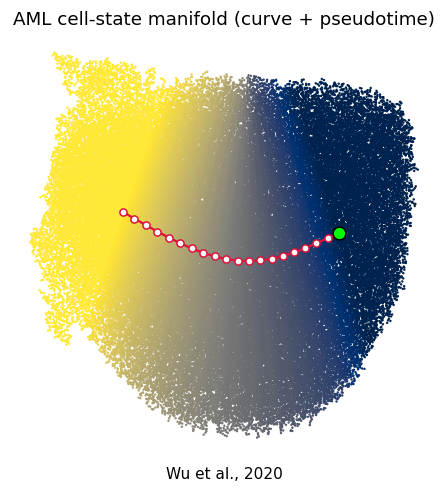

In [ ]:
# rename milestones (root=Origin, other tip=Terminus) for readability
scf.tl.rename_milestones(adata, new={str(root): 'M_root', str([t for t in tips if t!=root][0]): 'M_end'})
# manifold.pdf -- pseudotime coloured, WITH curve edges drawn (fold check, per 04_test Chen attempt 6)
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='t', cmap='cividis', size=10, colorbar_loc=None, frameon=False, show=False, ax=ax)
for i in range(F.shape[1]):
    for j in range(i+1, F.shape[1]):
        if B[i,j] > 0: ax.plot([F[0,i],F[0,j]], [F[1,i],F[1,j]], '-', color='crimson', lw=1.5, zorder=5)
ax.scatter(F[0], F[1], c='white', edgecolors='crimson', s=22, zorder=6)
ax.scatter(F[0,root], F[1,root], c='lime', edgecolors='k', s=70, zorder=7)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('AML cell-state manifold (curve + pseudotime)', size=12)
ax.text(.5, -.05, 'Wu et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_out, 'manifold.pdf'), bbox_inches='tight'); plt.show()

In [ ]:
# save manifold.h5ad (drop the non-serializable epg dict; keep graph + pseudotime)
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_in, 'manifold.h5ad'))
print('wrote manifold.h5ad', adata.shape)

wrote manifold.h5ad (96413, 13907)
